Imports

In [2]:
from Bio import SeqIO
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from collections import defaultdict
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import random
import re
import os

# 1. Datasets

## 1.1 - Positive Dataset

In [2]:
input_dir = Path("../data/domains_positive")

fasta_files = list(input_dir.glob("domain_*.fasta"))

output_file = input_dir / "all_DPO_candidates.fasta"

with open(output_file, "w") as outfile:
    for file in fasta_files:
        with open(file, "r") as infile:
            outfile.write(infile.read())

print(f"{len(fasta_files)} files combined into {output_file}")

7 files combined into ../data/domains_positive/all_DPO_candidates.fasta


### 1.1.1 - Remove hypothetical proteins from the positive and negative dataset

"Hypothetical protein" entries lack experimental or functional evidence.
They are excluded to keep the positive set biologically meaningful.

In [10]:
files = {
    "positive": {
        "input": Path("../data/domains_positive/all_DPO_candidates.fasta"),
        "output": Path("../data/domains_positive/all_DPO_positive.fasta"),
    },
    "negative": {
        "input": Path("../data/negative/negative.faa"),
        "output": Path("../data/negative/negative_nohyp.faa"),
    },
}

for label, paths in files.items():
    kept = []
    removed = 0

    for record in SeqIO.parse(paths["input"], "fasta"):
        header = record.description.lower()
        if "hypothetical" not in header:
            kept.append(record)
        else:
            removed += 1

    SeqIO.write(kept, paths["output"], "fasta")

    print(f"[{label}] Kept: {len(kept)}")
    print(f"[{label}] Removed: {removed}")

[positive] Kept: 1764
[positive] Removed: 277
[negative] Kept: 24929
[negative] Removed: 5071


Check for duplicates

In [11]:
files = {
    "positive": Path("../data/domains_positive/all_DPO_positive.fasta"),
    "negative": Path("../data/negative/negative_nohyp.faa"),
}

for label, input_fasta in files.items():
    seqs = [str(rec.seq) for rec in SeqIO.parse(input_fasta, "fasta")]
    total = len(seqs)
    unique = len(set(seqs))

    print(f"[{label}] Total sequences: {total}")
    print(f"[{label}] Unique sequences: {unique}")
    print(f"[{label}] Duplicates: {total - unique}")
    print()

[positive] Total sequences: 1764
[positive] Unique sequences: 1117
[positive] Duplicates: 647

[negative] Total sequences: 24929
[negative] Unique sequences: 23102
[negative] Duplicates: 1827



## 1.2 - Path definitions (Pre and Pos CD-HIT)

CD-HIT clusters sequences at a given identity threshold (here 80 %) and retains only one representative per cluster, reducing redundancy and preventing data leakage between splits.

In [4]:
positive = Path("../data/positive/all_DPO_positive_dedup.fasta")
negative = Path("../data/negative/negative_dedup.faa")

In [5]:
pos_cdhit = Path("../results/cdhit/positive_cdhit80.fasta")
neg_cdhit = Path("../results/cdhit/negative_cdhit80.fasta")

# 2. Sequence Lenght Analysis

In [15]:
def fasta_lengths(path: Path) -> pd.Series:
    lengths = [len(record.seq) for record in SeqIO.parse(path, "fasta")]
    return pd.Series(lengths, name="length")

In [16]:
pos_lengths = fasta_lengths(pos_cdhit)
neg_lengths = fasta_lengths(neg_cdhit)

print(pos_lengths.describe())
print(neg_lengths.describe())

count     593.000000
mean      732.548061
std       333.425138
min        99.000000
25%       583.000000
50%       708.000000
75%       837.000000
max      5096.000000
Name: length, dtype: float64
count    13377.000000
mean       620.321447
std        190.526422
min        400.000000
25%        474.000000
50%        570.000000
75%        709.000000
max       1250.000000
Name: length, dtype: float64


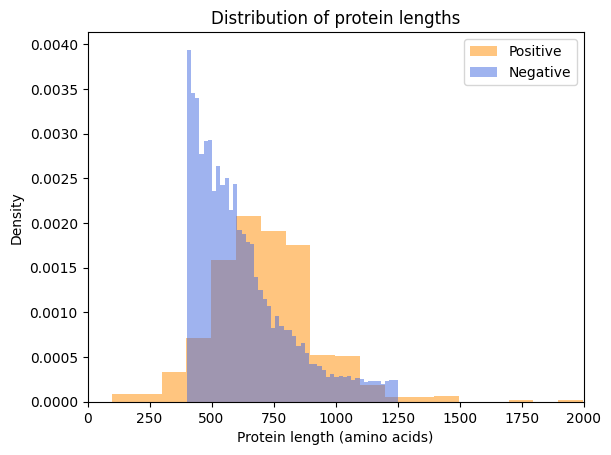

In [ ]:
plt.hist(pos_lengths, bins=50, alpha=0.5, label="Positive", density=True, color='darkorange')
plt.hist(neg_lengths, bins=50, alpha=0.5, label="Negative", density=True, color='royalblue')

plt.xlabel("Protein length (amino acids)")
plt.ylabel("Density")
plt.legend()
plt.title("Distribution of protein lengths")
plt.xlim(0, 2000)  
plt.show()

## 3. CD-HIT Reduncy: Before VS After

In [19]:
def count_fasta(path):
    return sum(1 for _ in SeqIO.parse(path, "fasta"))

before = [
    count_fasta(positive),
    count_fasta(negative)
]

after = [
    count_fasta(pos_cdhit),
    count_fasta(neg_cdhit)
]

In [20]:
df = pd.DataFrame({
    "Dataset": ["Positive", "Negative"],
    "Before CD-HIT": before,
    "After CD-HIT": after
})

df

,Dataset,Before CD-HIT,After CD-HIT
0,Positive,1117,593
1,Negative,23102,13377


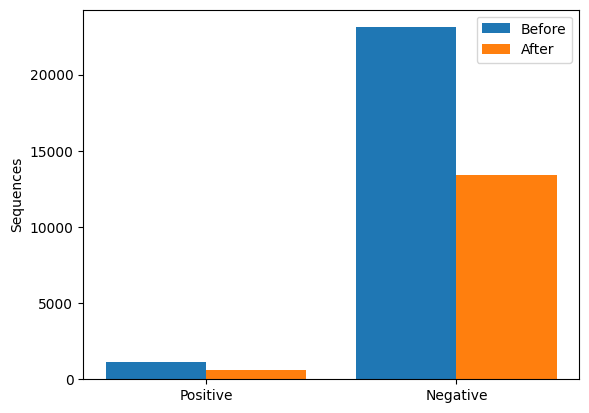

In [21]:
labels = ["Positive", "Negative"]
before 
after 

x = range(len(labels))

plt.bar(x, before, width=0.4, label="Before")
plt.bar([i+0.4 for i in x], after, width=0.4, label="After")

plt.xticks([i+0.2 for i in x], labels)
plt.ylabel("Sequences")
plt.legend()
plt.show()

## 4- Negative Sumsampling (1:2 positive-to-negative ratio for model development)

To avoid a severe class imbalance the negative set is randomly subsampled so that negatives are at most twice as numerous as positives. 

**random.seed(42)** makes the sample reproducible across runs.

In [25]:
# for reproducibility
random.seed(42)

# Load all sequences from FASTA
records = list(SeqIO.parse(neg_cdhit, "fasta"))

print(f"Total sequences: {len(records)}")

# Sample 1186 negatives
sample_size = 1186    # 593 * 2
sampled_records = random.sample(records, sample_size)

# Save sampled FASTA
SeqIO.write(sampled_records, "../data/negative/negative_sampled.fasta", "fasta")

print(f"Saved {len(sampled_records)} sampled sequences")

Total sequences: 13377
Saved 1186 sampled sequences


## 5- Merge positives and negatives (preliminary)

A preliminary merge assigns standardised sequential IDs (seq000001, …) and encodes label and original accession directly in the FASTA header so the file is self-describing.

In [26]:
merged_fasta = Path("../data/merged_input.fasta")
seq_counter = 1

with open(merged_fasta, "w") as out:
    # Add positives
    for rec in SeqIO.parse(pos_cdhit, "fasta"):
        new_id = f"seq{seq_counter:06d}"
        out.write(f">{new_id}|label=positive|orig_id={rec.id}\n{str(rec.seq)}\n")
        seq_counter += 1

    # Add negatives
    for rec in SeqIO.parse("../data/negative/negative_sampled.fasta", "fasta"):
        new_id = f"seq{seq_counter:06d}"
        out.write(f">{new_id}|label=negative|orig_id={rec.id}\n{str(rec.seq)}\n")
        seq_counter += 1

print(f"Merged FASTA saved to: {merged_fasta}")
print(f"Total sequences: {seq_counter - 1}")

Merged FASTA saved to: ../data/merged_input.fasta
Total sequences: 1779


In [27]:
# Quick sanity check — verify label counts in the merged file
pos_count = 0
neg_count = 0

for rec in SeqIO.parse(merged_fasta, "fasta"):
    if "label=positive" in rec.description:
        pos_count += 1
    elif "label=negative" in rec.description:
        neg_count += 1

print("Positives:", pos_count)
print("Negatives:", neg_count)

Positives: 593
Negatives: 1186


## 6- Full merge with metadata csv (for graphpart)

 GraphPart requires a FASTA with clean, unique headers. A richer metadata CSV (product name, organism, full description) is saved alongside it for downstream analysis.

In [6]:
merged_fasta = Path("../data/merged_input.fasta")
metadata_csv = Path("../data/merged_metadata.csv")

seq_counter = 1
rows = []

def parse_header_info(rec):
    desc = rec.description
    orig_id = rec.id

     # Strip the repeated accession prefix that Biopython includes in .description
    rest = desc[len(orig_id):].strip() if desc.startswith(orig_id) else desc

    # # Extract organism name enclosed in square brackets ([...]) 
    organism_match = re.search(r"\[(.*?)\]", rest)
    organism = organism_match.group(1) if organism_match else None

    # Remove the organism suffix to isolate the product/function description
    product = re.sub(r"\s*\[.*?\]\s*$", "", rest).strip() if rest else None

    return orig_id, product, organism, desc

with open(merged_fasta, "w") as out:
    # --- Positives ---
    for rec in SeqIO.parse(pos_cdhit, "fasta"):
        new_id = f"seq{seq_counter:06d}"
        orig_id, product, organism, full_description = parse_header_info(rec)
        seq = str(rec.seq)

        # Minimal header: GraphPart only needs unique IDs + label
        out.write(f">{new_id}|label=positive|orig_id={orig_id}\n{seq}\n")

        rows.append({
            "seq_id": new_id,
            "label": "positive",
            "orig_id": orig_id,
            "product": product,
            "organism": organism,
            "full_description": full_description,
            "sequence": seq
        })

        seq_counter += 1

    # --- Negatives ---
    for rec in SeqIO.parse("../data/negative/negative_sampled.fasta", "fasta"):
        new_id = f"seq{seq_counter:06d}"
        orig_id, product, organism, full_description = parse_header_info(rec)
        seq = str(rec.seq)

        out.write(f">{new_id}|label=negative|orig_id={orig_id}\n{seq}\n")

        rows.append({
            "seq_id": new_id,
            "label": "negative",
            "orig_id": orig_id,
            "product": product,
            "organism": organism,
            "full_description": full_description,
            "sequence": seq
        })

        seq_counter += 1

meta_df = pd.DataFrame(rows)

meta_df.to_csv(metadata_csv, index=False)

### 6.1 - Integrate Graphpart Assignments (60% threshold)

GraphPart partitions sequences into clusters based on pairwise similarity.

Cluster IDs are mapped to split names: 
- **0 → train**, 
- **1 → test**, 
- **2 → valid**

In [9]:
assign_df = pd.read_csv("../results/graphpart/graphpart_assignments_60.csv")

# Left-join so sequences not assigned by GraphPart appear with NaN in 'cluster'
full_60_df = meta_df.merge(assign_df, left_on="seq_id", right_on="AC", how="left")

In [10]:
cluster_to_split = {
    0.0: "train",
    1.0: "test",
    2.0: "valid"
}

full_60_df["split"] = full_60_df["cluster"].map(cluster_to_split)

In [11]:
print(full_60_df["cluster"].value_counts())
print(full_60_df["cluster"].value_counts(normalize=True).sort_index())

cluster
0.0    1513
1.0     176
2.0      90
Name: count, dtype: int64
cluster
0.0    0.850478
1.0    0.098932
2.0    0.050590
Name: proportion, dtype: float64


In [12]:
full_60_df

,seq_id,label,orig_id,product,organism,full_description,sequence,AC,priority,label-val,cluster,split
0,seq000001,positive,QXV78162.1,lateral tail fiber protein,Escherichia phage EmilieFrey,QXV78162.1 lateral tail fiber protein [Escheri...,MANFPTYPATTLEQGVDLVIFSSNQMHDVINGDATATVETETGLIP...,seq000001,False,0,2.0,valid
1,seq000002,positive,QAY00484.1,colanic acid-degrading protein,Escherichia phage Ecwhy_1,QAY00484.1 colanic acid-degrading protein [Esc...,MAVFSNLEGTMMPTFKLGKRGASINFVNDSVAIKDFLGETFLPVKV...,seq000002,False,0,0.0,train
2,seq000003,positive,QHR76167.1,putative colanic acid-degrading protein,Escherichia phage anhysbys,QHR76167.1 putative colanic acid-degrading pro...,MATFPTYPATSLEQGVDLVIFSSNQLHDVINGSATESIETESGLIP...,seq000003,False,0,0.0,train
3,seq000004,positive,YP_009792818.1,colanic acid degradation,Klebsiella phage vB_KpnS_IME279,YP_009792818.1 colanic acid degradation [Klebs...,MADLEVFSNLGMPSQPFFRNDRFAALANGKIYAGKADTDPTNPANQ...,seq000004,False,0,0.0,train
4,seq000005,positive,YP_009798895.1,colanic acid degradation,Klebsiella phage vB_KpnM_KpS110,YP_009798895.1 colanic acid degradation [Klebs...,MNPQFSQPGGSVSKDVNKQSIARTLGIKTSEVAYLKVGVSIAGVKT...,seq000005,False,0,0.0,train
...,...,...,...,...,...,...,...,...,...,...,...,...
1774,seq001775,negative,YP_013607573.1,RecD-like DNA helicase,Enterococcus phage vB_EfaS_140,YP_013607573.1 RecD-like DNA helicase [Enteroc...,MDFKRYNEREAKQYTAHLCYQLGIVYNIAKLIAEDEPTFTALNKAY...,seq001775,False,1,0.0,train
1775,seq001776,negative,YP_009600586.1,UNVERIFIED_ORG: putative helicase DEXDc superf...,Proteus phage VB_PmiS-Isfahan,YP_009600586.1 UNVERIFIED_ORG: putative helica...,MQPLRPHQVDAVERVSECWKAGDKDVCLVLPTGAGKTRVMAEFARL...,seq001776,False,1,0.0,train
1776,seq001777,negative,YP_009784694.1,DUF2828 domain-containing protein,Listeria phage LP-124,YP_009784694.1 DUF2828 domain-containing prote...,MSEFLNKLKEDTTLSKTEKGANTFSTTLDYNLDFFSRAGAMRDRTH...,seq001777,False,1,0.0,train
1777,seq001778,negative,YP_010779225.1,repeat protein,Moumouvirus goulette,YP_010779225.1 repeat protein [Moumouvirus gou...,MYYLFINNWRIKEIHNEFIKDGYTNEIFSLNNFVDNKIKLKFNYDW...,seq001778,False,1,0.0,train


In [13]:
output_path = Path("../data/final_dataset_60.csv")
full_60_df.to_csv(output_path, index=False)
print(f"Saved final dataset to: {output_path}")

Saved final dataset to: ../data/final_dataset_60.csv


### 6.2 Integrate Graphpart Assignments (40% Threshold)

A stricter 40 % identity threshold creates a harder generalisation benchmark: test sequences share less similarity with training sequences.

In [14]:
assign_df = pd.read_csv("../results/graphpart/graphpart_assignments_40.csv")

full_40_df = meta_df.merge(assign_df, left_on="seq_id", right_on="AC", how="left")

In [15]:
cluster_to_split = {
    0.0: "train",
    1.0: "test",
    2.0: "valid"
}

full_40_df["split"] = full_40_df["cluster"].map(cluster_to_split)

In [16]:
print(full_40_df["cluster"].value_counts())
print(full_40_df["cluster"].value_counts(normalize=True).sort_index())

cluster
0.0    1513
1.0     178
2.0      88
Name: count, dtype: int64
cluster
0.0    0.850478
1.0    0.100056
2.0    0.049466
Name: proportion, dtype: float64


In [17]:
full_40_df

,seq_id,label,orig_id,product,organism,full_description,sequence,AC,priority,label-val,cluster,split
0,seq000001,positive,QXV78162.1,lateral tail fiber protein,Escherichia phage EmilieFrey,QXV78162.1 lateral tail fiber protein [Escheri...,MANFPTYPATTLEQGVDLVIFSSNQMHDVINGDATATVETETGLIP...,seq000001,False,0,1.0,test
1,seq000002,positive,QAY00484.1,colanic acid-degrading protein,Escherichia phage Ecwhy_1,QAY00484.1 colanic acid-degrading protein [Esc...,MAVFSNLEGTMMPTFKLGKRGASINFVNDSVAIKDFLGETFLPVKV...,seq000002,False,0,1.0,test
2,seq000003,positive,QHR76167.1,putative colanic acid-degrading protein,Escherichia phage anhysbys,QHR76167.1 putative colanic acid-degrading pro...,MATFPTYPATSLEQGVDLVIFSSNQLHDVINGSATESIETESGLIP...,seq000003,False,0,0.0,train
3,seq000004,positive,YP_009792818.1,colanic acid degradation,Klebsiella phage vB_KpnS_IME279,YP_009792818.1 colanic acid degradation [Klebs...,MADLEVFSNLGMPSQPFFRNDRFAALANGKIYAGKADTDPTNPANQ...,seq000004,False,0,0.0,train
4,seq000005,positive,YP_009798895.1,colanic acid degradation,Klebsiella phage vB_KpnM_KpS110,YP_009798895.1 colanic acid degradation [Klebs...,MNPQFSQPGGSVSKDVNKQSIARTLGIKTSEVAYLKVGVSIAGVKT...,seq000005,False,0,0.0,train
...,...,...,...,...,...,...,...,...,...,...,...,...
1774,seq001775,negative,YP_013607573.1,RecD-like DNA helicase,Enterococcus phage vB_EfaS_140,YP_013607573.1 RecD-like DNA helicase [Enteroc...,MDFKRYNEREAKQYTAHLCYQLGIVYNIAKLIAEDEPTFTALNKAY...,seq001775,False,1,0.0,train
1775,seq001776,negative,YP_009600586.1,UNVERIFIED_ORG: putative helicase DEXDc superf...,Proteus phage VB_PmiS-Isfahan,YP_009600586.1 UNVERIFIED_ORG: putative helica...,MQPLRPHQVDAVERVSECWKAGDKDVCLVLPTGAGKTRVMAEFARL...,seq001776,False,1,0.0,train
1776,seq001777,negative,YP_009784694.1,DUF2828 domain-containing protein,Listeria phage LP-124,YP_009784694.1 DUF2828 domain-containing prote...,MSEFLNKLKEDTTLSKTEKGANTFSTTLDYNLDFFSRAGAMRDRTH...,seq001777,False,1,0.0,train
1777,seq001778,negative,YP_010779225.1,repeat protein,Moumouvirus goulette,YP_010779225.1 repeat protein [Moumouvirus gou...,MYYLFINNWRIKEIHNEFIKDGYTNEIFSLNNFVDNKIKLKFNYDW...,seq001778,False,1,0.0,train


In [18]:
output_path = Path("../data/final_dataset_40.csv")
full_40_df.to_csv(output_path, index=False)
print(f"Saved final dataset to: {output_path}")

Saved final dataset to: ../data/final_dataset_40.csv


In [ ]:
df = pd.read_csv("../data/final_dataset_40.csv")
df = df.drop_duplicates(subset="orig_id", keep="first")
df.to_csv("../data/final_dataset_40.csv", index=False)
print(f"Final shape: {df.shape}")  # (1778, 12)

Final shape: (1779, 12)


Graphpart 60% vs 40%

### 6.3 - Audit: Did Graphpart drop any sequences?

 GraphPart may silently exclude sequences it cannot assign to any cluster.
 This audit compares the original ID set against both split outputs to quantify any data loss before training.

In [30]:
original = pd.read_csv("../data/merged_metadata.csv") 
split_40 = pd.read_csv("../graphpart_assignments_40.csv")  
split_60 = pd.read_csv("../graphpart_assignments_60.csv")    

In [31]:
ids_original = set(original["seq_id"])
ids_split_40 = set(split_40["AC"])
ids_split_60 = set(split_60["AC"])

In [32]:
removed_40 = ids_original - ids_split_40
removed_60 = ids_original - ids_split_60
print("Original sequences:", len(ids_original))
print("Sequences in GraphPart output:", len(ids_split_40))
print("Removed / unassigned sequences:", len(removed_40))
print("Sequences in 40% split:", len(split_40))

print("Original sequences:", len(ids_original))
print("Sequences in GraphPart output:", len(ids_split_60))
print("Removed / unassigned sequences:", len(removed_60))
print("Sequences in 60% split:", len(split_60))

Original sequences: 1779
Sequences in GraphPart output: 1779
Removed / unassigned sequences: 0
Sequences in 40% split: 1779
Original sequences: 1779
Sequences in GraphPart output: 1779
Removed / unassigned sequences: 0
Sequences in 60% split: 1779


## 7. Build Domain Inventory CSV

Maps every protein accession to the domain file it was found in, enabling downstream analysis of which conserved domains are present in the positive set.

In [33]:
domains_dir = Path("../data/domains_positive")
print(domains_dir.exists())
print(list(domains_dir.glob("domain_*.fasta")))

True
[PosixPath('../data/domains_positive/domain_cl22684.fasta'), PosixPath('../data/domains_positive/domain_pfam13472.fasta'), PosixPath('../data/domains_positive/domain_pfam12708.fasta'), PosixPath('../data/domains_positive/domain_pfam07212.fasta'), PosixPath('../data/domains_positive/domain_pfam12219.fasta'), PosixPath('../data/domains_positive/domain_cd20481.fasta'), PosixPath('../data/domains_positive/domain_pfam12217.fasta')]


In [34]:
fasta_files = sorted(domains_dir.glob("domain_*.fasta"))

In [35]:
def extract_protein_ids_from_fasta(fasta_path):
    protein_ids = []

    with open(fasta_path, "r") as f:
        for line in f:
            if line.startswith(">"):
                header = line[1:].strip()
                protein_id = header.split()[0]
                protein_ids.append(protein_id)

    return protein_ids

In [36]:
all_rows = []

for fasta_file in fasta_files:
    domain_name = fasta_file.stem.split("domain_", 1)[-1]
    protein_ids = extract_protein_ids_from_fasta(fasta_file)

    for protein_id in protein_ids:
        all_rows.append({
            "protein_id": protein_id,
            "domain_file": fasta_file.name,
            "domain_name": domain_name
        })

domains_df = pd.DataFrame(all_rows)
domains_df.head()

,protein_id,domain_file,domain_name
0,ASN73455.2,domain_cd20481.fasta,cd20481
1,YP_009610433.1,domain_cd20481.fasta,cd20481
2,APD20249.1,domain_cd20481.fasta,cd20481
3,AYP68900.1,domain_cd20481.fasta,cd20481
4,ARB06757.1,domain_cd20481.fasta,cd20481


In [37]:
print("Number of rows:", len(domains_df))
print("Unique proteins:", domains_df["protein_id"].nunique())
print("Unique domains:", domains_df["domain_name"].nunique())

Number of rows: 2041
Unique proteins: 1949
Unique domains: 7


In [38]:
domains_df["domain_name"].value_counts()

domain_name
pfam12708    890
cd20481      492
pfam13472    209
pfam12219    155
cl22684      127
pfam07212    107
pfam12217     61
Name: count, dtype: int64

In [39]:
output_csv = Path("../data/protein_domains.csv")
domains_df.to_csv(output_csv, index=False)

print("Saved to:", output_csv)

Saved to: ../data/protein_domains.csv


## 8- Domain Analysis

### 8.1- Count domains per protein 

In [40]:
protein_domains = pd.read_csv("../data/protein_domains.csv")

In [41]:
domains_per_protein = (
    protein_domains.groupby("protein_id")
    .size()
    .reset_index(name="n_domains")
)

Proteins with multiple distinct domain annotations are of particular interest as they may carry catalytic domains from more than one family.


In [42]:
multi_domain_proteins = domains_per_protein[domains_per_protein["n_domains"] > 1]
multi_domain_proteins.head()

,protein_id,n_domains
4,AAC37340.1,2
13,AAZ73001.1,2
16,ABD90574.1,2
17,ABD90623.1,2
25,ABQ88383.1,2


In [43]:
print("Proteins with more than one domain:", len(multi_domain_proteins))

Proteins with more than one domain: 92


In [44]:
protein_domains = pd.read_csv("../data/protein_domains.csv")

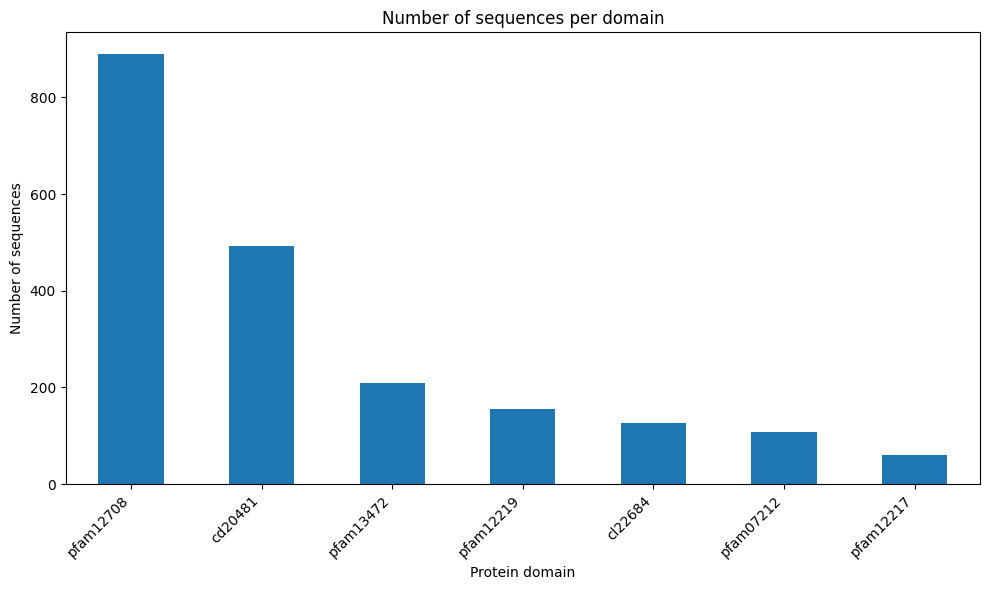

In [45]:
# Count sequences per domain
domain_counts = protein_domains["domain_name"].value_counts()

# Plot
plt.figure(figsize=(10, 6))
domain_counts.plot(kind="bar")

plt.xlabel("Protein domain")
plt.ylabel("Number of sequences")
plt.title("Number of sequences per domain")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 9- CD-HIT Cluster Parsing and Domain Tracking

The CD-HIT .clstr file records which proteins were grouped together and which one was selected as the cluster representative. Merging this with the domain inventory shows whether the retained representative carries the same domain annotations as the removed cluster members.

In [46]:
clstr_path = Path("../results/cdhit/all_DPO_positive_cdhit80.fasta.clstr")

In [47]:
clusters = []
current_cluster = None

with open(clstr_path, "r") as f:
    for line in f:
        line = line.strip()

        if line.startswith(">Cluster"):
            current_cluster = line.replace(">", "")
            continue
        
        # Each member line has the format:  0    123aa, >ACC.1... [*]
        # The trailing '*' marks the cluster representative.
        match = re.search(r">(.+?)\.\.\.", line)
        if match:
            protein_id = match.group(1)
            is_representative = line.endswith("*")

            clusters.append({
                "cluster_id": current_cluster,
                "protein_id": protein_id,
                "is_representative": is_representative
            })

cluster_df = pd.DataFrame(clusters)
cluster_df.head()

,cluster_id,protein_id,is_representative
0,Cluster 0,DAY75446.1,True
1,Cluster 1,DAW47699.1,True
2,Cluster 2,QBZ72050.1,True
3,Cluster 3,DAL46842.1,True
4,Cluster 4,QJD53722.1,True


In [48]:
# Build a lookup table: cluster_id → representative accession
rep_df = (
    cluster_df[cluster_df["is_representative"]]
    [["cluster_id", "protein_id"]]
    .rename(columns={"protein_id": "representative_id"})
)

rep_df.head()

,cluster_id,representative_id
0,Cluster 0,DAY75446.1
1,Cluster 1,DAW47699.1
2,Cluster 2,QBZ72050.1
3,Cluster 3,DAL46842.1
4,Cluster 4,QJD53722.1


In [49]:
# Annotate every cluster member with its representative
cluster_map_df = cluster_df.merge(rep_df, on="cluster_id", how="left")
cluster_map_df.head()

,cluster_id,protein_id,is_representative,representative_id
0,Cluster 0,DAY75446.1,True,DAY75446.1
1,Cluster 1,DAW47699.1,True,DAW47699.1
2,Cluster 2,QBZ72050.1,True,QBZ72050.1
3,Cluster 3,DAL46842.1,True,DAL46842.1
4,Cluster 4,QJD53722.1,True,QJD53722.1


In [50]:
# Join with domain annotations
tracked_df = cluster_map_df.merge(domains_df, on="protein_id", how="left")
tracked_df.head()

,cluster_id,protein_id,is_representative,representative_id,domain_file,domain_name
0,Cluster 0,DAY75446.1,True,DAY75446.1,domain_pfam13472.fasta,pfam13472
1,Cluster 1,DAW47699.1,True,DAW47699.1,domain_pfam13472.fasta,pfam13472
2,Cluster 2,QBZ72050.1,True,QBZ72050.1,domain_pfam12708.fasta,pfam12708
3,Cluster 3,DAL46842.1,True,DAL46842.1,domain_pfam12708.fasta,pfam12708
4,Cluster 4,QJD53722.1,True,QJD53722.1,domain_pfam12708.fasta,pfam12708


In [51]:
print("Proteins in clusters:", cluster_df["protein_id"].nunique())
print("Proteins with domains:", domains_df["protein_id"].nunique())
print("Proteins after merge:", tracked_df["protein_id"].nunique())

Proteins in clusters: 1684
Proteins with domains: 1949
Proteins after merge: 1684


In [52]:
# Rows where the protein IS the representative of its own cluster
rep_domains = tracked_df[
    tracked_df["protein_id"] == tracked_df["representative_id"]
]

### 9.1- Multi-domain Summay table

Lists proteins that carry more than one distinct domain, along with the full set of domain names concatenated as a semicolon-separated string.

In [53]:
domains_per_protein = (
    tracked_df.dropna(subset=["domain_name"])
    .groupby("protein_id")["domain_name"]
    .nunique()
    .reset_index(name="n_domains")
)

multi_domain_details = (
    tracked_df.dropna(subset=["domain_name"])
    .groupby("protein_id")["domain_name"]
    .agg(lambda x: "; ".join(sorted(set(x))))
    .reset_index(name="domains")
)

multi_domain_details = multi_domain_details.merge(
    domains_per_protein,
    on="protein_id",
    how="left"
)

multi_domain_details = multi_domain_details[
    multi_domain_details["n_domains"] > 1
].sort_values("n_domains", ascending=False)

multi_domain_details.head(20)

,protein_id,domains,n_domains
3,AAC37340.1,pfam12217; pfam12219,2
10,AAZ73001.1,pfam12217; pfam12219,2
13,ABD90574.1,cd20481; pfam12708,2
14,ABD90623.1,cd20481; pfam12708,2
22,ABQ88383.1,pfam12217; pfam12219,2
29,ADA82273.1,pfam12217; pfam12219,2
30,ADA82322.1,pfam12217; pfam12219,2
53,AFL46469.1,cd20481; pfam12708,2
88,AJA72945.1,cd20481; pfam12219,2
89,AJA73073.1,cd20481; pfam12219,2


### --- Cluster-level domain summary ---

In [54]:
cluster_summary = (
    tracked_df.dropna(subset=["domain_name"])
    .groupby("representative_id")
    .agg({
        "protein_id": "nunique",
        "domain_name": lambda x: ";".join(set(x))
    })
    .reset_index()
)

Compare domain counts before and after CD-HIT redundancy reduction

In [55]:
before = domains_df["domain_name"].value_counts()
after = rep_domains["domain_name"].value_counts()

In [56]:
before

domain_name
pfam12708    890
cd20481      492
pfam13472    209
pfam12219    155
cl22684      127
pfam07212    107
pfam12217     61
Name: count, dtype: int64

In [57]:
after

domain_name
pfam12708    357
cd20481      154
pfam13472     75
pfam12219     20
cl22684       15
pfam07212     11
pfam12217      6
Name: count, dtype: int64

## 10. Export Per-Split Fasta files (Needleman-Wunsch Alignment)

Separate FASTA files for each split partition are needed as input to pairwise Needleman–Wunsch alignment tools that verify there is no sequence leakage between training and evaluation sets.

In [20]:
datasets = {
    "40": {
        "df": pd.read_csv("../data/final_dataset_40.csv"),
        "out_dir": Path("../alignment/40_percent"),
    },
    "60": {
        "df": pd.read_csv("../data/final_dataset_60.csv"),
        "out_dir": Path("../alignment/60_percent"),
    },
}

for pct, cfg in datasets.items():
    df = cfg["df"].copy()
    out_dir = cfg["out_dir"]
    out_dir.mkdir(parents=True, exist_ok=True)

    print(f"\nGraphPart {pct}%")
    print(df["split"].value_counts())

    for split_name in ["train", "test", "valid"]:
        split_df = df[df["split"] == split_name].copy()

        records = []

        for _, row in split_df.iterrows():
            record_id = str(row["orig_id"])
            sequence = str(row["sequence"])

            record = SeqRecord(
                Seq(sequence),
                id=record_id,
                description=""
            )

            records.append(record)

        out_path = out_dir / f"{pct}pct_{split_name}.fasta"
        SeqIO.write(records, out_path, "fasta")

        print(f"{split_name}: wrote {len(records)} sequences to {out_path}")


GraphPart 40%
split
train    1513
test      178
valid      88
Name: count, dtype: int64
train: wrote 1513 sequences to ../alignment/40_percent/40pct_train.fasta
test: wrote 178 sequences to ../alignment/40_percent/40pct_test.fasta
valid: wrote 88 sequences to ../alignment/40_percent/40pct_valid.fasta

GraphPart 60%
split
train    1513
test      176
valid      90
Name: count, dtype: int64
train: wrote 1513 sequences to ../alignment/60_percent/60pct_train.fasta
test: wrote 176 sequences to ../alignment/60_percent/60pct_test.fasta
valid: wrote 90 sequences to ../alignment/60_percent/60pct_valid.fasta


## 11. Split Verification

Confirm that each partition contains both classes and that the overall distribution is balanced before training any model.

In [21]:
df_40 = pd.read_csv("../data/final_dataset_40.csv")
df_60 = pd.read_csv("../data/final_dataset_60.csv")

train_40 = df_40[df_40["split"] == "train"].copy()
val_40 = df_40[df_40["split"] == "valid"].copy()
test_40 = df_40[df_40["split"] == "test"].copy()

train_60 = df_60[df_60["split"] == "train"].copy()
val_60 = df_60[df_60["split"] == "valid"].copy()
test_60 = df_60[df_60["split"] == "test"].copy()

print(f"\nGraphPart 40%")
print(train_40.shape)
print(val_40.shape)
print(test_40.shape)

print(f"\nGraphPart 60%")
print(train_60.shape)
print(val_60.shape)
print(test_60.shape)


GraphPart 40%
(1513, 12)
(88, 12)
(178, 12)

GraphPart 60%
(1513, 12)
(90, 12)
(176, 12)


In [22]:
print(f"\nGraphPart 40%")
print(train_40["label"].value_counts())
print(val_40["label"].value_counts())
print(test_40["label"].value_counts())

print(f"\nGraphPart 60%")
print(train_60["label"].value_counts())
print(val_60["label"].value_counts())
print(test_60["label"].value_counts())


GraphPart 40%
label
negative    1008
positive     505
Name: count, dtype: int64
label
negative    59
positive    29
Name: count, dtype: int64
label
negative    119
positive     59
Name: count, dtype: int64

GraphPart 60%
label
negative    1008
positive     505
Name: count, dtype: int64
label
negative    60
positive    30
Name: count, dtype: int64
label
negative    118
positive     58
Name: count, dtype: int64


Overall DPO vs. Non-DPO counts

In [23]:
counts_40 = df_40["label"].value_counts()
counts_60 = df_60["label"].value_counts()

print(f"\nGraphPart 40%")
print("Non-DPO:", counts_40.iloc[0])
print("DPO:", counts_40.iloc[1])

print(f"\nGraphPart 60%")
print("Non-DPO:", counts_60.iloc[0])
print("DPO:", counts_60.iloc[1])


GraphPart 40%
Non-DPO: 1186
DPO: 593

GraphPart 60%
Non-DPO: 1186
DPO: 593


## 12. Embedding Shape Summary

Quick sanity check: verify that the number of rows in each embedding array matches the dataset size and inspect the embedding dimensionality.

In [25]:
df = pd.read_csv('../data/final_dataset_40.csv')
for model in ['esm', 'bert', 'prott5']:
    meta = pd.read_csv(f'../results/embeddings/{model}_metadata.csv')
    match = (meta['orig_id'].values == df['orig_id'].values).all()
    print(f'{model}: rows={len(meta)}, aligned={match}')

esm: rows=1779, aligned=True
bert: rows=1779, aligned=True
prott5: rows=1779, aligned=True


In [26]:
esm = np.load("../results/embeddings/esm_embeddings.npy")
protbert = np.load("../results/embeddings/bert_embeddings.npy")
prott5 = np.load("../results/embeddings/prott5_embeddings.npy")

In [27]:
models = {
    "ESM": esm,
    "ProtBERT": protbert,
    "ProtT5": prott5
}

for name, emb in models.items():
    dpo = emb[df["label"] == "positive"].shape[0]
    nondpo = emb[df["label"] == "negative"].shape[0]

    print(f"{name}")
    print("DPO:", dpo)
    print("Non-DPO:", nondpo)
    print()

ESM
DPO: 593
Non-DPO: 1186

ProtBERT
DPO: 593
Non-DPO: 1186

ProtT5
DPO: 593
Non-DPO: 1186



In [28]:
summary = pd.DataFrame({
    "Model": ["ESM", "ProtBERT", "ProtT5"],
    "Rows (Proteins)": [esm.shape[0], protbert.shape[0], prott5.shape[0]],
    "Columns (Dimensions)": [esm.shape[1], protbert.shape[1], prott5.shape[1]]
})

display(summary)

,Model,Rows (Proteins),Columns (Dimensions)
0,ESM,1779,1280
1,ProtBERT,1779,1024
2,ProtT5,1779,1024


## 13- DNN Evaluation

Evaluate the pre-trained DNN classifier for each embedding type. Metrics and confusion matrices are produced for both the validation and test sets.

In [29]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

print(PROJECT_ROOT)

/home/mcarvalho/Thesis


In [30]:
from nn.metrics import evaluate_model, plot_confusion_matrix, create_eval_loaders
from nn.dnn import DNNClassifier
import torch

In [31]:
device = torch.device("cpu")
split_dir = "../results/embeddings/split"

### ESM

In [32]:
embedding_name = "esm"

val_loader, test_loader, input_dim = create_eval_loaders(
    split_dir=split_dir,
    embedding_name=embedding_name,
    batch_size=32
)

In [33]:
model = DNNClassifier(input_dim=input_dim).to(device)

model.load_state_dict(
    torch.load(f"../results/models/dnn_{embedding_name}.pt", map_location=device)
)

model.eval()

DNNClassifier(
  (model): Sequential(
    (0): Linear(in_features=1280, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=256, out_features=64, bias=True)
    (9): ReLU()
    (10): Dropout(p=0.2, inplace=False)
    (11): Linear(in_features=64, out_features=1, bias=True)
  )
)

In [34]:
val_metrics, val_cm = evaluate_model(model, val_loader, device)
test_metrics, test_cm = evaluate_model(model, test_loader, device)

print("Validation:", val_metrics)
print("Test:", test_metrics)

Validation: {'precision': 0.9642857142857143, 'recall': 0.9310344827586207, 'f1_score': 0.9473684210526315}
Test: {'precision': 0.8983050847457628, 'recall': 0.8983050847457628, 'f1_score': 0.8983050847457628}


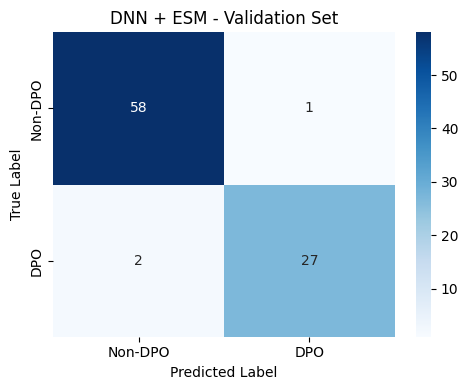

In [37]:
plot_confusion_matrix(
    val_cm,
    title="DNN + ESM - Validation Set"
)

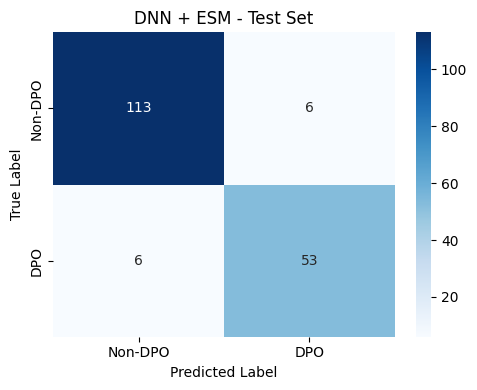

In [38]:
plot_confusion_matrix(
    test_cm,
    title="DNN + ESM - Test Set"
)

### ProtT5

In [39]:
embedding_name = "prott5"
val_loader, test_loader, input_dim = create_eval_loaders(
    split_dir=split_dir,
    embedding_name=embedding_name,
    batch_size=32
)

In [40]:
model = DNNClassifier(input_dim=input_dim).to(device)

model.load_state_dict(
    torch.load(f"../results/models/dnn_{embedding_name}.pt", map_location=device)
)

<All keys matched successfully>

In [41]:
val_metrics, val_cm = evaluate_model(model, val_loader, device)
test_metrics, test_cm = evaluate_model(model, test_loader, device)

print("Validation ProtT5:", val_metrics)
print("Test ProtT5:", test_metrics)

Validation ProtT5: {'precision': 0.9666666666666667, 'recall': 1.0, 'f1_score': 0.9830508474576272}
Test ProtT5: {'precision': 0.8428571428571429, 'recall': 1.0, 'f1_score': 0.9147286821705426}


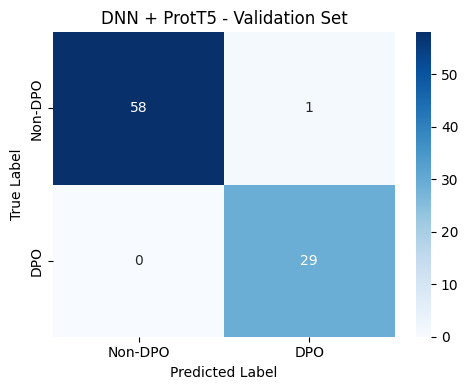

In [42]:
plot_confusion_matrix(
    val_cm,
    title="DNN + ProtT5 - Validation Set"
)

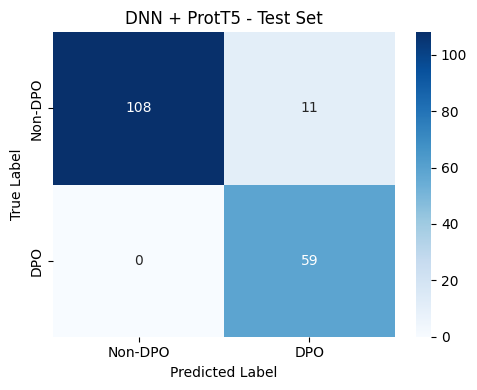

In [43]:
plot_confusion_matrix(
    test_cm,
    title="DNN + ProtT5 - Test Set"
)

### ProtBert

In [44]:
embedding_name = "bert"
val_loader, test_loader, input_dim = create_eval_loaders(
    split_dir=split_dir,
    embedding_name=embedding_name,
    batch_size=32
)

In [45]:
model = DNNClassifier(input_dim=input_dim).to(device)

model.load_state_dict(
    torch.load(f"../results/models/dnn_{embedding_name}.pt", map_location=device)
)

<All keys matched successfully>

In [46]:
val_metrics, val_cm = evaluate_model(model, val_loader, device)
test_metrics, test_cm = evaluate_model(model, test_loader, device)

print("Validation ProtBert:", val_metrics)
print("Test ProtBert:", test_metrics)

Validation ProtBert: {'precision': 0.9354838709677419, 'recall': 1.0, 'f1_score': 0.9666666666666667}
Test ProtBert: {'precision': 0.7866666666666666, 'recall': 1.0, 'f1_score': 0.8805970149253731}


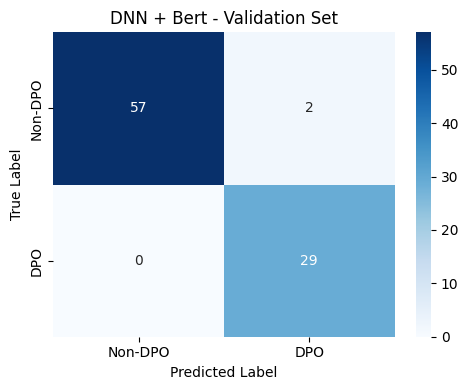

In [47]:
plot_confusion_matrix(
    val_cm,
    title="DNN + Bert - Validation Set"
)

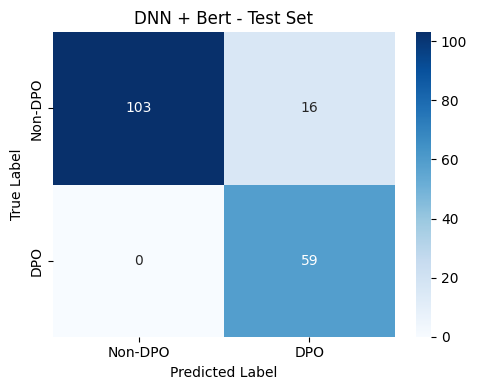

In [48]:
plot_confusion_matrix(
    test_cm,
    title="DNN + Bert - Test Set"
)

In [49]:
# Does the order of rows in the embedding match the CSV?
df = pd.read_csv("../data/final_dataset_40.csv")  # or whichever you use

esm = np.load("../results/embeddings/esm_embeddings.npy")

print(f"CSV rows: {len(df)}, ESM rows: {esm.shape[0]}")

# Check the split file alignment
esm_val = np.load("../results/embeddings/split/esm_val.npy")
y_val = np.load("../results/embeddings/split/y_val.npy")

print(f"esm_val rows: {esm_val.shape[0]}, y_val rows: {y_val.shape[0]}")

# Are the val labels what you expect?
print(f"Val class distribution: DPO={y_val.sum()}, Non-DPO={(y_val==0).sum()}")

CSV rows: 1779, ESM rows: 1779
esm_val rows: 88, y_val rows: 88
Val class distribution: DPO=29.0, Non-DPO=59


In [50]:
# Load the metadata saved BY the embedding script
esm_meta = pd.read_csv("../results/embeddings/esm_metadata.csv")
bert_meta = pd.read_csv("../results/embeddings/bert_metadata.csv")
prott5_meta = pd.read_csv("../results/embeddings/prott5_metadata.csv")

# Load the dataset with the split column
df = pd.read_csv("../data/final_dataset_40.csv")

print("Dataset rows:", len(df))
print("ESM metadata rows:", len(esm_meta))
print("BERT metadata rows:", len(bert_meta))
print("ProtT5 metadata rows:", len(prott5_meta))

# Are the IDs identical and in the same order?
print("\nESM IDs match dataset:", (esm_meta["orig_id"].values == df["orig_id"].values).all())
print("BERT IDs match dataset:", (bert_meta["orig_id"].values == df["orig_id"].values).all())

Dataset rows: 1779
ESM metadata rows: 1779
BERT metadata rows: 1779
ProtT5 metadata rows: 1779

ESM IDs match dataset: True
BERT IDs match dataset: True


## 14- CNN EVALUATION


In [51]:
from nn.metrics import evaluate_model, plot_confusion_matrix, create_eval_loaders
from nn.cnn import CNNClassifier
import torch

### ESM

In [52]:
embedding_name = "esm"
split_dir = "../results/embeddings/split"

In [53]:
val_loader, test_loader, input_dim = create_eval_loaders(
    split_dir=split_dir,
    embedding_name=embedding_name,
    batch_size=32
)

In [54]:
model = CNNClassifier(input_dim=input_dim).to(device)

model.load_state_dict(
    torch.load(f"../results/models/cnn_{embedding_name}.pt", map_location=device)
)

model.eval()

CNNClassifier(
  (conv1): Conv1d(1, 64, kernel_size=(5,), stride=(1,), padding=(2,))
  (bn1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv1d(64, 128, kernel_size=(5,), stride=(1,), padding=(2,))
  (bn2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): AdaptiveMaxPool1d(output_size=1)
  (classifier): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)

In [55]:
val_metrics, val_cm = evaluate_model(model, val_loader, device)
test_metrics, test_cm = evaluate_model(model, test_loader, device)


print("Validation:", val_metrics)
print("Test:", test_metrics)

Validation: {'precision': 0.8928571428571429, 'recall': 0.8620689655172413, 'f1_score': 0.8771929824561403}
Test: {'precision': 0.765625, 'recall': 0.8305084745762712, 'f1_score': 0.7967479674796748}


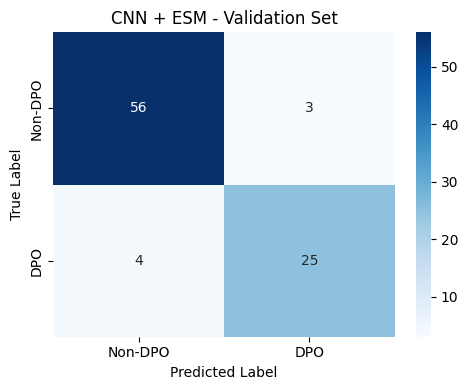

In [56]:
plot_confusion_matrix(
    val_cm,
    title="CNN + ESM - Validation Set"
)

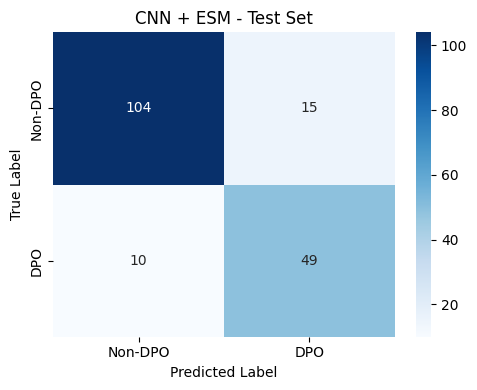

In [57]:
plot_confusion_matrix(
    test_cm,
    title="CNN + ESM - Test Set"
)

### ProtT5

In [58]:
embedding_name = "prott5"
split_dir = "../results/embeddings/split"

In [59]:
val_loader, test_loader, input_dim = create_eval_loaders(
    split_dir=split_dir,
    embedding_name=embedding_name,
    batch_size=32
)

In [60]:
model = CNNClassifier(input_dim=input_dim).to(device)

model.load_state_dict(
    torch.load(f"../results/models/cnn_{embedding_name}.pt", map_location=device)
)

<All keys matched successfully>

In [61]:
val_metrics, val_cm = evaluate_model(model, val_loader, device)
test_metrics, test_cm = evaluate_model(model, test_loader, device)


print("Validation:", val_metrics)
print("Test:", test_metrics)

Validation: {'precision': 0.9354838709677419, 'recall': 1.0, 'f1_score': 0.9666666666666667}
Test: {'precision': 0.8405797101449275, 'recall': 0.9830508474576272, 'f1_score': 0.90625}


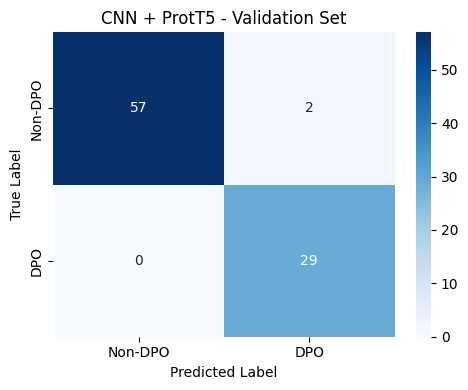

In [62]:
plot_confusion_matrix(
    val_cm,
    title="CNN + ProtT5 - Validation Set"
)

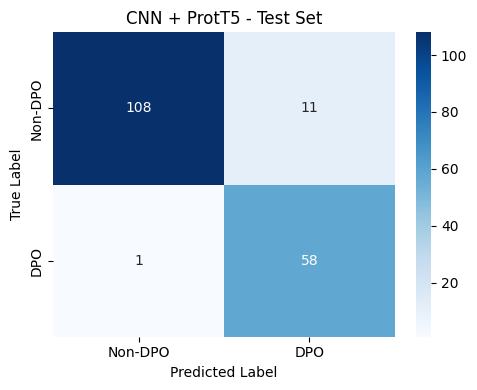

In [63]:
plot_confusion_matrix(
    test_cm,
    title="CNN + ProtT5 - Test Set"
)

### ProtBert

In [64]:
embedding_name = "bert"
split_dir = "../results/embeddings/split"

In [65]:
val_loader, test_loader, input_dim = create_eval_loaders(
    split_dir=split_dir,
    embedding_name=embedding_name,
    batch_size=32
)

In [66]:
model = CNNClassifier(input_dim=input_dim).to(device)

model.load_state_dict(
    torch.load(f"../results/models/cnn_{embedding_name}.pt", map_location=device)
)

<All keys matched successfully>

In [67]:
val_metrics, val_cm = evaluate_model(model, val_loader, device)
test_metrics, test_cm = evaluate_model(model, test_loader, device)


print("Validation:", val_metrics)
print("Test:", test_metrics)

Validation: {'precision': 0.84, 'recall': 0.7241379310344828, 'f1_score': 0.7777777777777778}
Test: {'precision': 0.75, 'recall': 0.8135593220338984, 'f1_score': 0.7804878048780488}


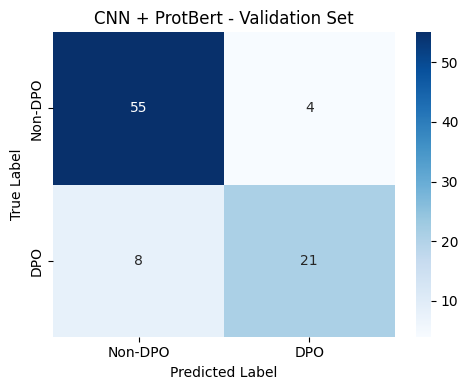

In [68]:
plot_confusion_matrix(
    val_cm,
    title="CNN + ProtBert - Validation Set"
)

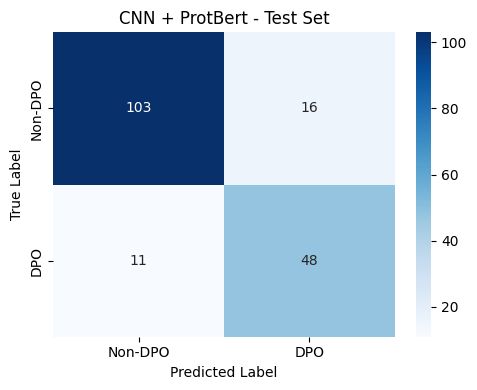

In [69]:
plot_confusion_matrix(
    test_cm,
    title="CNN + ProtBert - Test Set"
)

## 15- Training vs. Validation Loss Curves

 Loss curves reveal whether a model is **overfitting** (val loss rises while train loss falls), **underfitting** (both losses remain high), or converging normally. Plotted for every model-architecture combination.

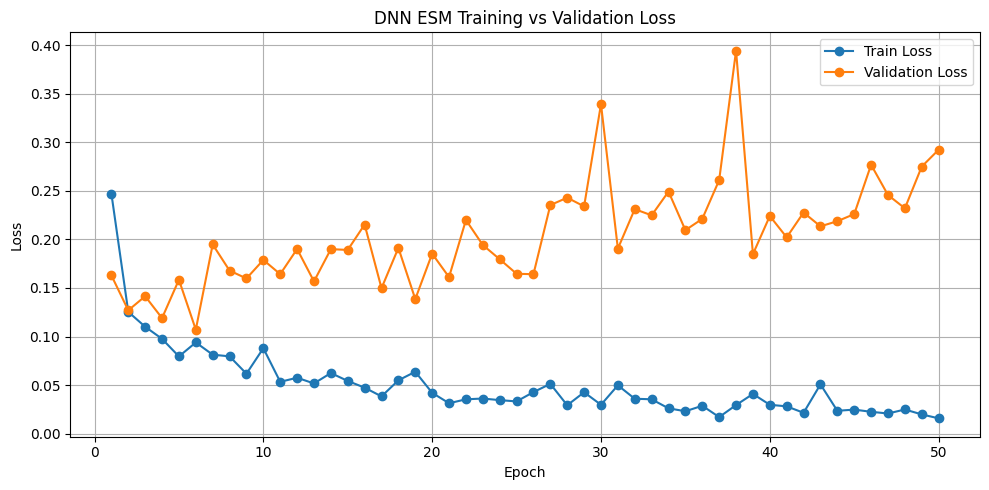

In [70]:
df = pd.read_csv("../results/history/dnn_esm_history.csv")

epochs = df["epoch"]

plt.figure(figsize=(10,5))

plt.plot(epochs, df["train_loss"], marker="o", label="Train Loss")
plt.plot(epochs, df["val_loss"], marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DNN ESM Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

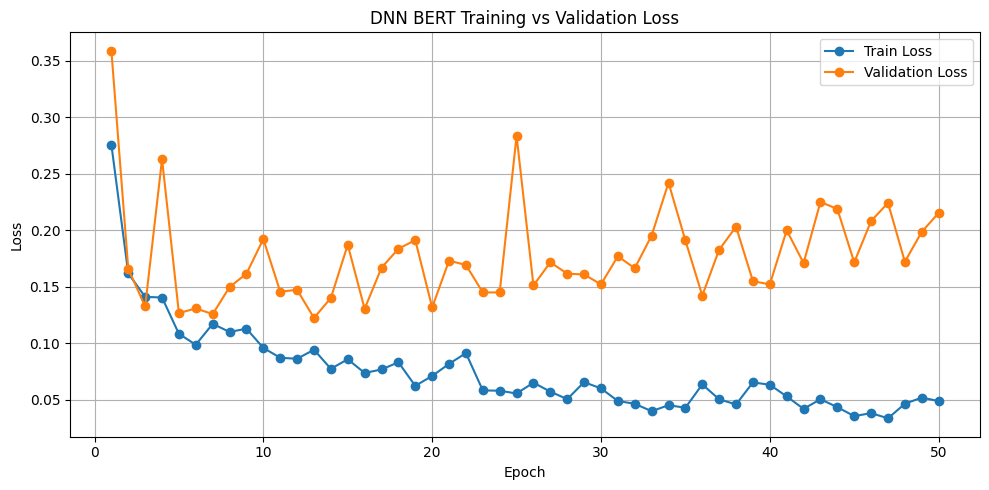

In [71]:
df = pd.read_csv("../results/history/dnn_bert_history.csv")

epochs = df["epoch"]

plt.figure(figsize=(10,5))

plt.plot(epochs, df["train_loss"], marker="o", label="Train Loss")
plt.plot(epochs, df["val_loss"], marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DNN BERT Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

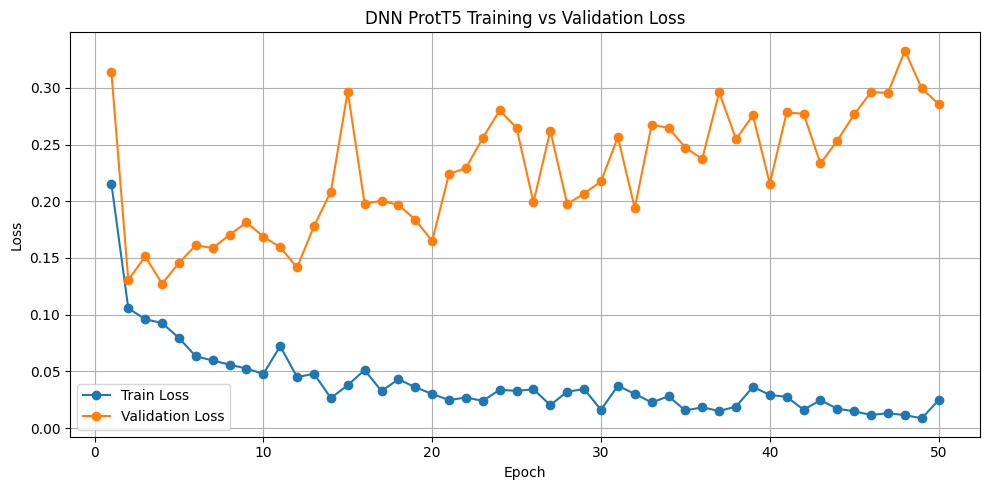

In [72]:
df = pd.read_csv("../results/history/dnn_prott5_history.csv")

epochs = df["epoch"]

plt.figure(figsize=(10,5))

plt.plot(epochs, df["train_loss"], marker="o", label="Train Loss")
plt.plot(epochs, df["val_loss"], marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DNN ProtT5 Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

CNN

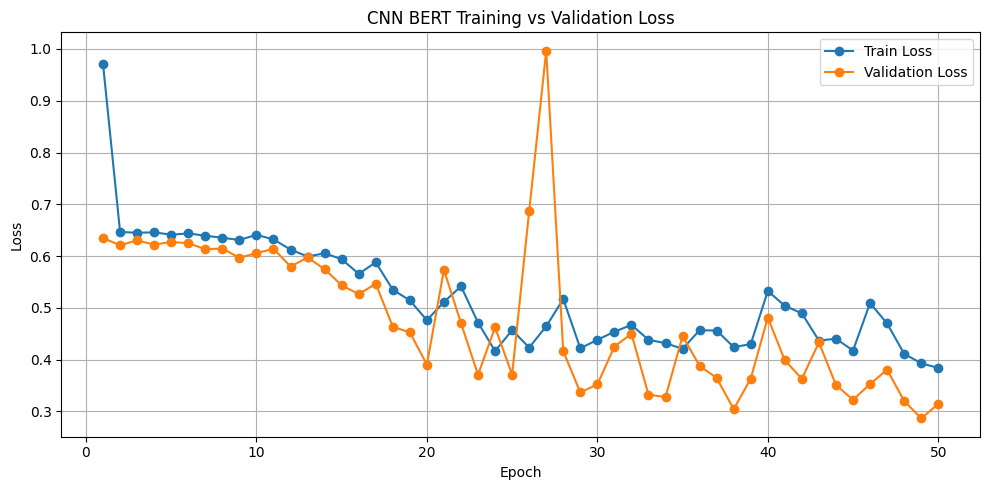

In [73]:
df = pd.read_csv("../results/history/cnn_bert_history.csv")

epochs = df["epoch"]

plt.figure(figsize=(10,5))

plt.plot(epochs, df["train_loss"], marker="o", label="Train Loss")
plt.plot(epochs, df["val_loss"], marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN BERT Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

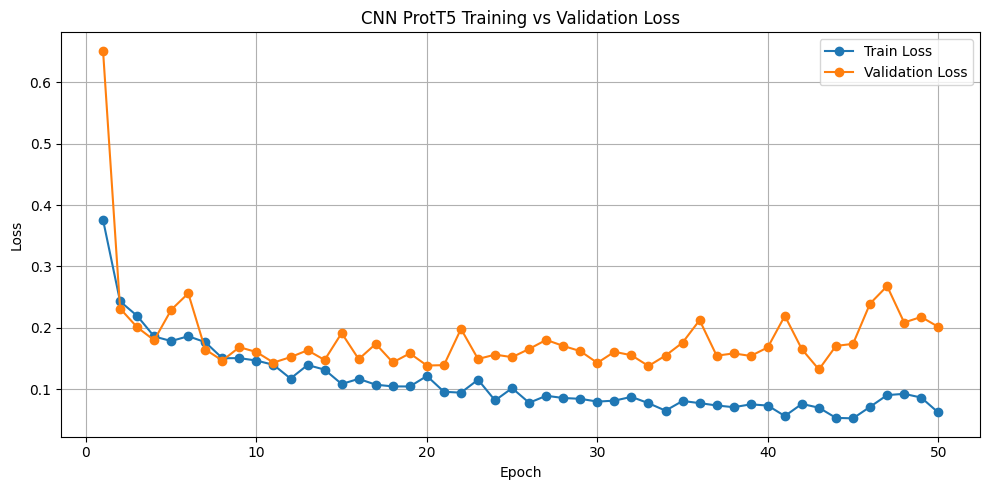

In [74]:
df = pd.read_csv("../results/history/cnn_prott5_history.csv")

epochs = df["epoch"]

plt.figure(figsize=(10,5))

plt.plot(epochs, df["train_loss"], marker="o", label="Train Loss")
plt.plot(epochs, df["val_loss"], marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN ProtT5 Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

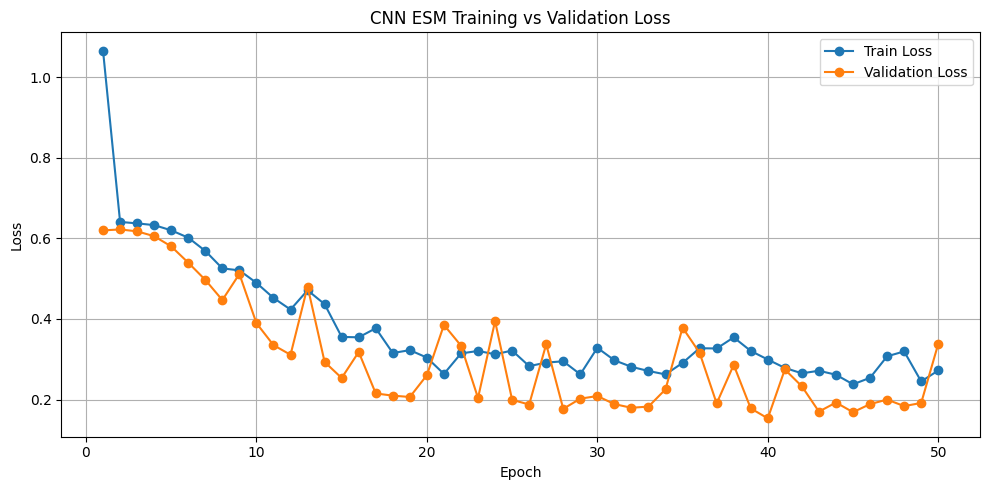

In [75]:
df = pd.read_csv("../results/history/cnn_esm_history.csv")

epochs = df["epoch"]

plt.figure(figsize=(10,5))

plt.plot(epochs, df["train_loss"], marker="o", label="Train Loss")
plt.plot(epochs, df["val_loss"], marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN ESM Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [78]:
import pandas as pd

df = pd.read_csv('../results/graphpart/graphpart_assignments_40.csv')  # confirma o nome exato do teu ficheiro atual
print(df['cluster'].value_counts())  # ou a coluna que indica train/val/test

train_ids = set(df[df['cluster'] == 0]['AC'])  # ajusta nomes de coluna aos teus
val_ids = set(df[df['cluster'] == 1]['AC'])
test_ids = set(df[df['cluster'] == 2]['AC'])

print("Overlap train-val:", train_ids & val_ids)
print("Overlap train-test:", train_ids & test_ids)
print("Overlap val-test:", val_ids & test_ids)

cluster
0.0    1513
1.0     178
2.0      88
Name: count, dtype: int64
Overlap train-val: set()
Overlap train-test: set()
Overlap val-test: set()


## DEPOSCOPE

==================================================
TEST SET RESULTS — DepoScope (retrained CNN head)
==================================================
  F1          : 0.8333
  Precision   : 0.8197
  Recall      : 0.8475
  AUC         : 0.8833
  Accuracy    : 0.8876
==================================================

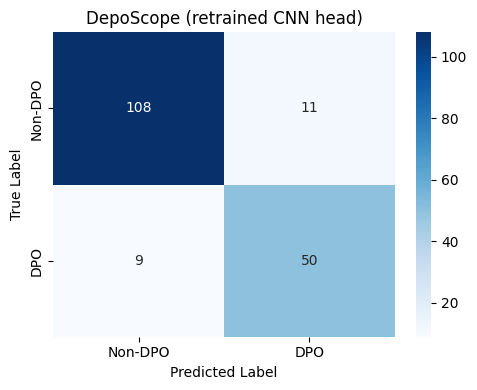

In [79]:
from sklearn.metrics import confusion_matrix

probs = np.load('../results/deposcope_retrain/test_probabilities.npy').squeeze()

df = pd.read_csv('../data/final_dataset_40.csv')
test_df = df[df['split'] == 'test'].reset_index(drop=True)
labels = (test_df['label'] == 'positive').astype(int).values

preds = (probs >= 0.5).astype(int)

cm = confusion_matrix(labels, preds)
plot_confusion_matrix(cm, title="DepoScope (retrained CNN head)")